Reference: flag nobody = 1.106, flag everybody = 0.779

Logistic Regression -> best cutoff 0.16, cost 0.555
   cutoff 0.50: precision 0.678  recall 0.352  F1 0.463  accuracy 0.820  cost 0.754
   cutoff 0.16: precision 0.381  recall 0.738  F1 0.502  accuracy 0.676  cost 0.555
Decision Tree -> best cutoff 0.19, cost 0.568
   cutoff 0.50: precision 0.667  recall 0.369  F1 0.475  accuracy 0.820  cost 0.739
   cutoff 0.19: precision 0.389  recall 0.710  F1 0.502  accuracy 0.689  cost 0.568
Random Forest -> best cutoff 0.17, cost 0.543
   cutoff 0.50: precision 0.684  recall 0.360  F1 0.472  accuracy 0.822  cost 0.745
   cutoff 0.17: precision 0.385  recall 0.748  F1 0.508  accuracy 0.680  cost 0.543
XGBoost -> best cutoff 0.18, cost 0.548
   cutoff 0.50: precision 0.682  recall 0.366  F1 0.476  accuracy 0.822  cost 0.739
   cutoff 0.18: precision 0.412  recall 0.705  F1 0.520  accuracy 0.712  cost 0.548


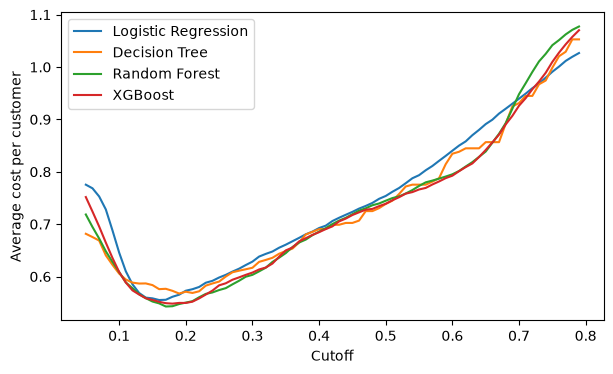

In [1]:
import sys
sys.path.append("..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score
from src.features import split_xy
from src.tune import load_tuned_models

COST_FN = 5   # cost of a missed defaulter (assumption)
COST_FP = 1   # cost of a false alarm (assumption)

train = pd.read_csv("../data/processed/train.csv")
X, y = split_xy(train)
yv = y.values
cv = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 42)

oof = {name: cross_val_predict(m, X, y, cv = cv, method = "predict_proba")[:, 1]
       for name, m in load_tuned_models().items()}

def cost_per_customer(p, t):
    pred = p >= t
    missed = ((~pred) & (yv == 1)).sum()
    false_alarm = (pred & (yv == 0)).sum()
    return (COST_FN * missed + COST_FP * false_alarm) / len(yv)

print(f"Reference: flag nobody = {COST_FN * yv.mean():.3f}, flag everybody = {COST_FP * (1 - yv.mean()):.3f}\n")

thresholds = np.arange(0.05, 0.80, 0.01)
fig, ax = plt.subplots(figsize = (7, 4))
for name, p in oof.items():
    costs = [cost_per_customer(p, t) for t in thresholds]
    best_t = thresholds[int(np.argmin(costs))]
    ax.plot(thresholds, costs, label=name)
    print(name, f"-> best cutoff {best_t:.2f}, cost {min(costs):.3f}")
    for t in [0.5, best_t]:
        pred = p >= t
        print(f"   cutoff {t:.2f}: precision {precision_score(yv, pred):.3f}  recall {recall_score(yv, pred):.3f}  "
              f"F1 {f1_score(yv, pred):.3f}  accuracy {accuracy_score(yv, pred):.3f}  cost {cost_per_customer(p, t):.3f}")
ax.set_xlabel("Cutoff")
ax.set_ylabel("Average cost per customer")
ax.legend()
plt.show()

Best cutoff is about 0.16 to 0.19 for all models (5 per miss, 1 per false alarm). Moving from 0.5 to the best cutoff raises recall from about 35-37% to 71-75% and lowers accuracy from about 82% to 68-71%. Cost per customer falls from about 0.74-0.75 to 0.54-0.57.